# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly, per the spec renumbering rule.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends
of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that pair: we
score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal /
neural-crest FOXC and PRRX factors** (the Kürten lesson: widen beyond Snail/Zeb/Twist) — along
*this* trajectory (gastrulation/somitogenesis body → neural-crest terminus), gated on detectable
expression, and report **where they actually sit** rather than forcing a root↔terminus pair. The
honest result (below): the EMT programme is **terminus-loaded** — every expressed factor leans
late and the strongest (ZEB2) marks the neural-crest terminus, with **no root-end EMT-TF**.
Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 2734 | pseudotime range 0.0 -> 11.74


### Derive the EMT-TF distribution along pseudotime (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Factors below a 3%
expression floor are too sparse to overlay (the Kürten detection-gate rule; VIM etc. excluded as
non-TF markers by construction — only transcription factors are in the panel).

**Honest readout — the EMT programme is terminus-loaded, mirroring Qian's root/loaded finding but
in the opposite direction.** *Every* sufficiently-expressed factor is classified `LATE(terminus)`
by its own tercile means (mean_late ≥ mean_early), and the two strongest ones (ZEB2 ρ=+0.26, SNAI1
ρ=+0.13) concentrate at the neural-crest terminus. **There is no root-end EMT-TF**: the least-terminal
expressed factor (FOXC1, ρ=−0.017 — essentially flat) is still mildly terminus-biased (its
upper-quartile cells sit at pseudotime 0.53 vs a population mean of 0.47). We therefore do **not**
claim an early→late EMT pair. The overlay contrasts the **most terminus-concentrated** factor
(**ZEB2**) against the **least-terminal / most body-distributed** expressed factor (**FOXC1**, which
surfaced only because the panel was widened to the FOXC/PRRX factors per the Kürten lesson) — to show
that EMT-TF expression rises toward the mesenchymal / neural-crest terminus, not that it spans a root
→ terminus axis.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
n_early = int((ok.end == 'EARLY(root)').sum())
# terminus factor = most terminus-concentrated (max rho); body factor = least terminal (min rho)
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
body_tf     = ok.sort_values('rho_vs_t').iloc[0]['TF']
print(f'\nexpressed EMT-TFs classified EARLY(root): {n_early} of {len(ok)} '
      f'-> the EMT programme is {"terminus-loaded (no root-end factor)" if n_early==0 else "split"}')
print(f'terminus factor (max rho) = {terminus_tf}; least-terminal / body factor (min rho) = {body_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
TWIST2      0.016       0.008      0.005    -0.057    EARLY(root)
 FOXC1      0.084       0.014      0.020    -0.005 LATE(terminus)
 FOXC2      0.003       0.000      0.003     0.025 LATE(terminus)
 SNAI2      0.105       0.017      0.038     0.037 LATE(terminus)
 PRRX2      0.013       0.002      0.010     0.047 LATE(terminus)
TWIST1      0.002       0.000      0.004     0.070 LATE(terminus)
 SNAI1      0.037       0.004      0.041     0.100 LATE(terminus)
  ZEB1      0.057       0.004      0.050     0.124 LATE(terminus)
 PRRX1      0.011       0.000      0.023     0.125 LATE(terminus)
  ZEB2      0.076       0.004      0.146     0.268 LATE(terminus)

expressed EMT-TFs classified EARLY(root): 0 of 5 -> the EMT programme is terminus-loaded (no root-end factor)
terminus factor (max rho) = ZEB2; least-terminal / body factor (min rho) = FOXC1


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Draw order is set by abundance
(the more widely-expressed factor first, the sparser one on top) so neither marker is fully
occluded. Each factor is thresholded at the upper quartile of expression among its expressing cells,
so only the strongest expressers show and the early (blue) / late (red) regions separate. This
categorical overlay of thresholded expressers on a grey manifold is the reference plotting style
(not a continuous single-gene colormap).

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.344, 'ZEB2': 0.978} | cells shown: {'FOXC1': 57, 'ZEB2': 52}
FOXC1: 8.4% expressing; 57 shown (upper quartile), mean pseudotime of shown cells = 0.58 (all cells = 0.48)
ZEB2: 7.6% expressing; 52 shown (upper quartile), mean pseudotime of shown cells = 0.99 (all cells = 0.48)
shown-cell pseudotime shift (ZEB2 terminus - FOXC1 body) = +0.41 (both terminus-biased; ZEB2 more so)
EMT programme is terminus-loaded: no root-end EMT-TF; expression rises toward the neural-crest terminus
saved expression.pdf


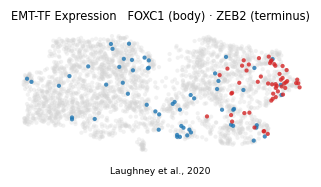

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [body_tf, terminus_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [body_tf, terminus_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [body_tf, terminus_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [body_tf, terminus_tf]})
order = sorted([body_tf, terminus_tf], key=lambda g: -int(sel[g].sum()))
colors = {body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (body) · {terminus_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Laughney et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [body_tf, terminus_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[terminus_tf]].mean() - tn[sel[body_tf]].mean()
print(f'shown-cell pseudotime shift ({terminus_tf} terminus - {body_tf} body) = {sep:+.2f} '
      f'(both terminus-biased; {terminus_tf} more so)')
print('EMT programme is terminus-loaded: no root-end EMT-TF; expression rises toward the neural-crest terminus')
print('saved expression.pdf')